# REINFORCE (policy gradient): blood delivery drone


## 1. Setup

In [1]:
import os
import sys
import random

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical
from collections import deque

# Run from the project root so that `environment/` can be imported.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

from environment.custom_env import BloodDroneEnv, MASK_START, mask_scores

env = BloodDroneEnv()
STATE_SIZE = env.observation_space.shape[0]   # 43 numbers describe the drone and its surroundings
NUM_ACTIONS = env.action_space.n              # 9 actions
print("State size:", STATE_SIZE, "| Actions:", NUM_ACTIONS)


State size: 43 | Actions: 9


## 2. Helper functions

`make_net` builds a small neural network.

In [2]:
EPISODES = 500          # training episodes for every experiment
REWARD_SCALE = 0.1      # smaller rewards for training only (helps stability)


def make_net(inputs, hidden, outputs):
    """A small neural network: inputs -> hidden layers -> one score per action."""
    layers, size = [], inputs
    for h in hidden:
        layers += [nn.Linear(size, h), nn.ReLU()]
        size = h
    layers.append(nn.Linear(size, outputs))
    return nn.Sequential(*layers)


## 3. The REINFORCE agent

`train_reinforce` trains one agent for 500 episodes and returns the reward of every episode and the loss values.

In [3]:
def train_reinforce(config, episodes=EPISODES):
    """Train one REINFORCE agent. Returns the reward of every episode and the loss values."""
    random.seed(0); np.random.seed(0); torch.manual_seed(0)
    env = BloodDroneEnv(practice=0.8)   # the same training setting as training/reinforce_training.py

    policy = make_net(STATE_SIZE, config["hidden"], NUM_ACTIONS)
    optimizer = optim.Adam(policy.parameters(), lr=config["lr"])
    rewards, losses = [], []

    for episode in range(episodes):
        state, _ = env.reset()
        done = False
        log_probs, entropies, step_rewards = [], [], []

        # 1. Play one full episode with the current policy.
        while not done:
            obs = torch.tensor(state)
            dist = Categorical(logits=mask_scores(policy(obs), obs))
            action = dist.sample()
            state, reward, terminated, truncated, _ = env.step(action.item())
            done = terminated or truncated
            log_probs.append(dist.log_prob(action))
            entropies.append(dist.entropy())
            step_rewards.append(reward * REWARD_SCALE)

        # 2. The discounted return of every step.
        returns, g = [], 0.0
        for r in reversed(step_rewards):
            g = r + config["gamma"] * g
            returns.insert(0, g)
        returns = torch.tensor(returns, dtype=torch.float32)
        if config["normalize_returns"]:
            returns = (returns - returns.mean()) / (returns.std() + 1e-8)

        # 3. Make actions that led to good returns more likely (policy gradient).
        loss = -(torch.stack(log_probs) * returns).mean() - config["entropy_coeff"] * torch.stack(entropies).mean()
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(policy.parameters(), 0.5)
        optimizer.step()

        losses.append(loss.item())
        rewards.append(sum(step_rewards) / REWARD_SCALE)

    return rewards, losses


## 4. The 10 experiments

Experiment 1 is the baseline. In each of the other nine experiments only one hyperparameter is changed.

In [4]:
reinforce_configs = [
    {"name": "REINFORCE-1", "lr": 0.001, "gamma": 0.99, "hidden": (64, 64), "normalize_returns": True, "entropy_coeff": 0.01},
    {"name": "REINFORCE-2", "lr": 0.0003, "gamma": 0.99, "hidden": (64, 64), "normalize_returns": True, "entropy_coeff": 0.01},
    {"name": "REINFORCE-3", "lr": 0.0001, "gamma": 0.99, "hidden": (64, 64), "normalize_returns": True, "entropy_coeff": 0.01},
    {"name": "REINFORCE-4", "lr": 0.001, "gamma": 0.95, "hidden": (64, 64), "normalize_returns": True, "entropy_coeff": 0.01},
    {"name": "REINFORCE-5", "lr": 0.001, "gamma": 0.999, "hidden": (64, 64), "normalize_returns": True, "entropy_coeff": 0.01},
    {"name": "REINFORCE-6", "lr": 0.001, "gamma": 0.99, "hidden": (32, 32), "normalize_returns": True, "entropy_coeff": 0.01},
    {"name": "REINFORCE-7", "lr": 0.001, "gamma": 0.99, "hidden": (128, 128), "normalize_returns": True, "entropy_coeff": 0.01},
    {"name": "REINFORCE-8", "lr": 0.001, "gamma": 0.99, "hidden": (64, 64), "normalize_returns": False, "entropy_coeff": 0.01},
    {"name": "REINFORCE-9", "lr": 0.001, "gamma": 0.99, "hidden": (64, 64), "normalize_returns": True, "entropy_coeff": 0.0},
    {"name": "REINFORCE-10", "lr": 0.001, "gamma": 0.99, "hidden": (64, 64), "normalize_returns": True, "entropy_coeff": 0.05},
]

## 5. Run the experiments

In [5]:
results = []      # one row per experiment
curves = {}       # reward of every episode, for the plots

for config in reinforce_configs:
    rewards, losses = train_reinforce(config)
    curves[config["name"]] = rewards
    results.append({
        "experiment": config["name"],
        "average reward": round(float(np.mean(rewards)), 1),
        "last 100": round(float(np.mean(rewards[-100:])), 1),
        "loss": round(float(np.mean(losses)), 3),
    })
    print(config["name"], "| average:", results[-1]["average reward"], "| last 100:", results[-1]["last 100"], "| loss:", results[-1]["loss"])

REINFORCE-1 | average: -99.2 | last 100: -85.0 | loss: -0.029


REINFORCE-2 | average: -112.2 | last 100: -114.9 | loss: -0.035


REINFORCE-3 | average: -111.2 | last 100: -111.7 | loss: -0.035


REINFORCE-4 | average: -108.2 | last 100: -104.5 | loss: -0.037


REINFORCE-5 | average: -96.4 | last 100: -75.2 | loss: -0.056


REINFORCE-6 | average: -110.7 | last 100: -103.9 | loss: -0.029


REINFORCE-7 | average: -114.2 | last 100: -106.9 | loss: -0.041


REINFORCE-8 | average: -113.4 | last 100: -113.8 | loss: -13.884


REINFORCE-9 | average: -105.8 | last 100: -111.6 | loss: 0.004


REINFORCE-10 | average: -104.0 | last 100: -98.7 | loss: -0.108


## 6. Results

In [6]:
print(f"{'experiment':<14}{'average reward':>16}{'last 100':>12}{'loss':>10}")
for row in results:
    print(f"{row['experiment']:<14}{row['average reward']:>16}{row['last 100']:>12}{row['loss']:>10}")

experiment      average reward    last 100      loss
REINFORCE-1              -99.2       -85.0    -0.029
REINFORCE-2             -112.2      -114.9    -0.035
REINFORCE-3             -111.2      -111.7    -0.035
REINFORCE-4             -108.2      -104.5    -0.037
REINFORCE-5              -96.4       -75.2    -0.056
REINFORCE-6             -110.7      -103.9    -0.029
REINFORCE-7             -114.2      -106.9    -0.041
REINFORCE-8             -113.4      -113.8   -13.884
REINFORCE-9             -105.8      -111.6     0.004
REINFORCE-10            -104.0       -98.7    -0.108


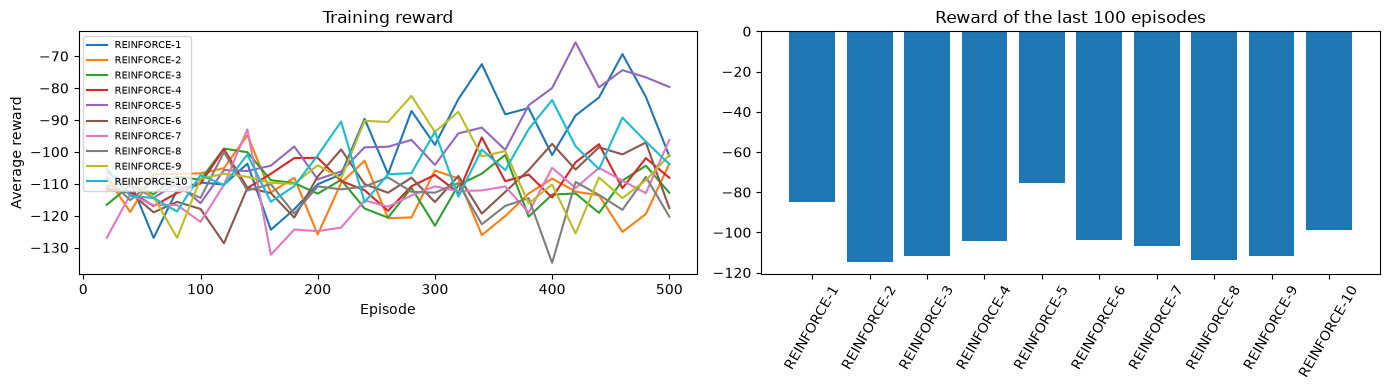

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# learning curves (average of every 20 episodes)
for name, rewards in curves.items():
    smooth = [np.mean(rewards[i:i + 20]) for i in range(0, len(rewards), 20)]
    axes[0].plot(range(20, len(rewards) + 1, 20), smooth, label=name)
axes[0].set_title("Training reward")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Average reward")
axes[0].legend(fontsize=7)

# reward of the last 100 episodes of every experiment (what the agent learned)
axes[1].bar([row["experiment"] for row in results], [row["last 100"] for row in results])
axes[1].set_title("Reward of the last 100 episodes")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

## 7. Best hyperparameters

The best experiment is the one with the highest average reward in its last 100 episodes, because that shows what the agent has learned (the early episodes are mostly random exploration). These values are the ones to use in `training/reinforce_training.py`.

In [8]:
# the best experiment has the highest reward in its last 100 episodes (smaller loss breaks a tie)
best = sorted(results, key=lambda row: (-row["last 100"], row["loss"]))[0]
best_config = next(c for c in reinforce_configs if c["name"] == best["experiment"])

print("Best experiment:", best["experiment"])
print("Last 100 episodes:", best["last 100"], "| average:", best["average reward"], "| loss:", best["loss"])
print("Best hyperparameters:")
for key, value in best_config.items():
    if key != "name":
        print("  ", key, "=", value)

Best experiment: REINFORCE-5
Last 100 episodes: -75.2 | average: -96.4 | loss: -0.056
Best hyperparameters:
   lr = 0.001
   gamma = 0.999
   hidden = (64, 64)
   normalize_returns = True
   entropy_coeff = 0.01
